# 📊 Klasifikasi Kondisi Area Rak Sepatu Menggunakan Model Machine Learning Klasik

Proyek ini bertujuan untuk mengklasifikasikan kondisi area depan laboratorium / rak sepatu menjadi 3 kategori:
- **`berantakan`**: Sepatu berserakan atau tidak berada pada posisinya.
- **`rapi`**: Sepatu tersusun rapi di dalam rak sepatu.
- **`kosong`**: Rak sepatu dan lantai bersih tanpa ada sepatu/sandal.

### 🔬 Fitur Citra yang Digunakan
Fitur yang diekstraksi dari citra meliputi 16 fitur visual:
1. **Color Moments**: Nilai statistik warna pada kanal RGB dan Grayscale (`R_mean`, `G_mean`, `B_mean`, `R_std`, `G_std`, `B_std`, `R_skew`, `G_skew`, `B_skew`, `gray_skew`).
2. **GLCM Haralick Textures**: Fitur tekstur matriks co-occurrence spasial (`glcm_contrast`, `glcm_dissimilarity`, `glcm_homogeneity`, `glcm_energy`, `glcm_correlation`, `glcm_asm`).

### ⚙️ Alur Tahapan Klasifikasi:
1. **Import Library & Persiapan Lingkungan**
2. **Load Dataset & Eksplorasi Data (EDA)**
3. **Pembagian Dataset (Stratified Train-Test Split 80:20)**
4. **Pelatihan Berbagai Model Machine Learning Klasik & 5-Fold Cross-Validation**
5. **Perbandingan Performa Model & Pemilihan Model Terbaik**
6. **Evaluasi Mendalam Model Terbaik (Confusion Matrix & Classification Report)**
7. **Analisis Feature Importance (Kontribusi Fitur Visual Terpenting)**
8. **Penyimpanan Model Terbaik (`.joblib`) & Uji Prediksi (Inference Test)**


## 1. Import Library & Persiapan Lingkungan
Memuat pustaka standar untuk manipulasi data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), algoritma machine learning (`scikit-learn`), dan penyimpanan model (`joblib`).


In [1]:
import os
import io
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Algoritma Klasifikasi Klasik
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier

# Sklearn Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Konfigurasi Tampilan Plot
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42
print("Semua library berhasil diimpor dengan sukses!")


Semua library berhasil diimpor dengan sukses!


## 2. Load Dataset & Eksplorasi Data (EDA)
Membaca dataset hasil ekstraksi fitur visual `fitur_citra_lengkap.csv` dan memeriksa distribusi kelas serta kelengkapan data.


In [2]:
# Load dataset fitur
csv_path = 'fitur_citra_lengkap.csv'
df = pd.read_csv(csv_path)

print(f"Bentuk Dataset: {df.shape[0]} sampel baris, {df.shape[1]} kolom")
print(f"Jumlah Missing Values: {df.isnull().sum().sum()} nilai kosong")
print("\nDistribusi Sampel per Kelas:")
distribusi = df['label'].value_counts()
for label, count in distribusi.items():
    print(f"  - {label:<12}: {count} gambar ({count/len(df)*100:.1f}%)")

# Tampilkan 5 baris teratas
display(df.head())


Bentuk Dataset: 245 sampel baris, 18 kolom
Jumlah Missing Values: 0 nilai kosong

Distribusi Sampel per Kelas:
  - berantakan  : 110 gambar (44.9%)
  - rapi        : 93 gambar (38.0%)
  - kosong      : 42 gambar (17.1%)


,file_name,label,R_mean,G_mean,B_mean,R_std,G_std,B_std,R_skew,G_skew,B_skew,gray_skew,glcm_contrast,glcm_dissimilarity,glcm_homogeneity,glcm_energy,glcm_correlation,glcm_asm
0,IMG-20261105-WA0052.jpg,rapi,115.922516,115.263855,108.083150,50.596110,56.355553,63.412247,0.267057,0.187625,0.036101,-0.007178,61.337570,2.787149,0.533626,0.035841,0.988874,0.001285
1,IMG-20261105-WA0110.jpg,rapi,106.447460,103.808420,102.343000,56.783990,67.670540,68.218650,0.201589,0.206170,0.165386,0.235651,228.535188,10.640404,0.113326,0.012989,0.972051,0.000169
2,IMG-20261108-WA0005.jpg,rapi,133.887190,132.574520,129.505280,69.461780,70.083680,71.092060,-0.362826,-0.249410,-0.019462,-0.294189,169.758153,6.579182,0.305140,0.018922,0.982294,0.000358
3,IMG-20261108-WA0006.jpg,rapi,151.563960,152.696910,151.400710,58.094456,59.934067,65.895860,-0.768609,-0.746395,-0.734284,-0.765781,164.649147,5.053656,0.454082,0.032928,0.975516,0.001084
4,IMG-20261109-WA0025.jpeg,rapi,128.475780,129.721560,126.583496,52.227160,60.273647,65.082504,-0.151009,-0.193221,-0.410312,-0.146324,59.773633,3.167272,0.451198,0.031922,0.990779,0.001019


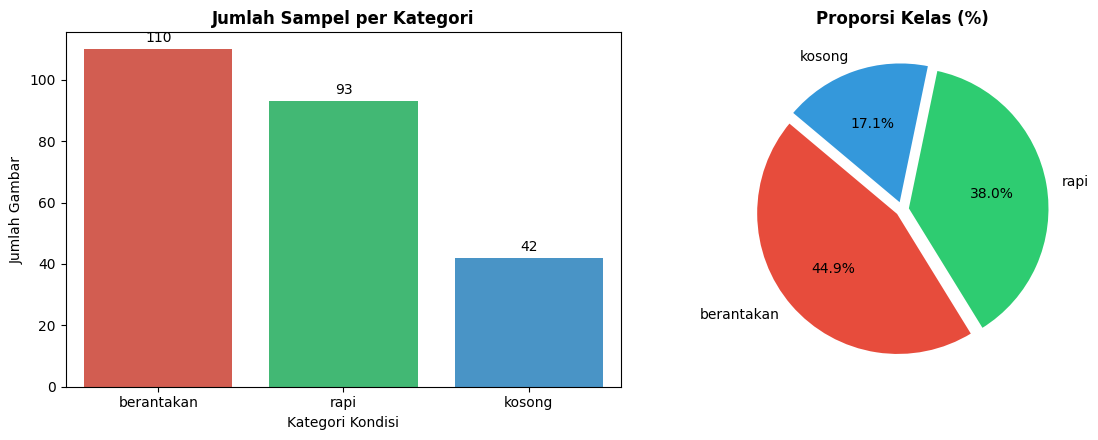

In [3]:
# Visualisasi Distribusi Kelas
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar plot
palette = ['#e74c3c', '#2ecc71', '#3498db']
sns.barplot(x=distribusi.index, y=distribusi.values, palette=palette, ax=axes[0], hue=distribusi.index, legend=False)
axes[0].set_title('Jumlah Sampel per Kategori', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kategori Kondisi', fontsize=10)
axes[0].set_ylabel('Jumlah Gambar', fontsize=10)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Pie chart
axes[1].pie(distribusi.values, labels=distribusi.index, autopct='%1.1f%%',
            startangle=140, colors=palette, explode=(0.04, 0.04, 0.04),
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Proporsi Kelas (%)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Pembagian Dataset (Stratified Train-Test Split)
Memisahkan fitur independen ($X$) dan label target ($y$).
Dataset dibagi menjadi:
- **80% Data Latih (Train Set)**: Untuk melatih model dan validasi silang (cross-validation).
- **20% Data Uji (Test Set)**: Untuk evaluasi akhir performa model pada data baru.
- Menggunakan parameter `stratify=y` dan `random_state=42` agar proporsi ketiga kelas seimbang secara merata di data latih dan uji.


In [4]:
# Pisahkan fitur dan label
X = df.drop(columns=['file_name', 'label'])
y = df['label']
feature_names = X.columns.tolist()

# Train-test split (80:20) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Total Fitur Visual yang Digunakan: {len(feature_names)}")
print(f"Jumlah Data Latih (Train Set)    : {len(X_train)} sampel ({len(X_train)/len(df)*100:.1f}%)")
print(f"Jumlah Data Uji (Test Set)       : {len(X_test)} sampel ({len(X_test)/len(df)*100:.1f}%)")
print("\nDistribusi Kelas pada Data Latih:")
print(y_train.value_counts())
print("\nDistribusi Kelas pada Data Uji:")
print(y_test.value_counts())


Total Fitur Visual yang Digunakan: 16
Jumlah Data Latih (Train Set)    : 196 sampel (80.0%)
Jumlah Data Uji (Test Set)       : 49 sampel (20.0%)

Distribusi Kelas pada Data Latih:
label
berantakan    88
rapi          74
kosong        34
Name: count, dtype: int64

Distribusi Kelas pada Data Uji:
label
berantakan    22
rapi          19
kosong         8
Name: count, dtype: int64


## 4. Pelatihan Berbagai Model Machine Learning Klasik & Cross-Validation
Pada tahap ini, kita menguji dan membandingkan **8 algoritma machine learning klasik**:
1. **Logistic Regression (Multinomial)**: Model linier dengan normalisasi `StandardScaler`.
2. **Support Vector Machine (SVM - RBF Kernel)**: Memetakan fitur ke ruang dimensi tinggi dengan margin optimal.
3. **k-Nearest Neighbors (k-NN, k=5)**: Klasifikasi berbasis jarak tetangga terdekat dengan fitur terstandarisasi.
4. **Gaussian Naive Bayes**: Klasifikasi probabilistik mengasumsikan independensi fitur.
5. **Decision Tree Classifier**: Algoritma pohon keputusan berbasis partisi informasi (Gini Impurity).
6. **Random Forest Classifier**: Ensemble pohon keputusan acak (Bagging) untuk meminimalkan varians.
7. **Extra Trees Classifier (Extremely Randomized Trees)**: Varian ensemble pohon dengan ambang split acak untuk generalisasi superior.
8. **Gradient Boosting Classifier**: Ensemble berbasis Boosting yang mengoreksi kesalahan residual secara iteratif.

Evaluasi kestabilan model diuji menggunakan **5-Fold Stratified Cross-Validation** pada data latih.


In [5]:
# Definisi Model Klasik yang Diuji
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Support Vector Machine (SVM)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))
    ]),
    'k-Nearest Neighbors (k-NN)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Gaussian Naive Bayes': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', GaussianNB())
    ]),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    )
}

# 5-Fold Stratified Cross Validation pada Data Latih
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
trained_models = {}

print("Memulai pelatihan dan evaluasi 5-Fold Cross-Validation...\n" + "="*65)
for name, model in models.items():
    # Hitung skor CV pada data train
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()
    
    # Latih model pada seluruh data train
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    # Uji prediksi pada data test yang belum pernah dilihat
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    test_prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    test_rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    test_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    results.append({
        'Model': name,
        'CV Accuracy Mean': cv_mean,
        'CV Accuracy Std': cv_std,
        'Test Accuracy': test_acc,
        'Test Precision': test_prec,
        'Test Recall': test_rec,
        'Test F1-Score': test_f1
    })
    print(f"[{name:<28}] CV Acc: {cv_mean*100:6.2f}% (+/- {cv_std*100:5.2f}%) | Test Acc: {test_acc*100:6.2f}% | Test F1: {test_f1*100:6.2f}%")

print("="*65 + "\nEvaluasi seluruh model selesai!")


Memulai pelatihan dan evaluasi 5-Fold Cross-Validation...
[Logistic Regression         ] CV Acc:  73.45% (+/-  5.60%) | Test Acc:  75.51% | Test F1:  74.60%
[Support Vector Machine (SVM)] CV Acc:  72.91% (+/-  5.44%) | Test Acc:  71.43% | Test F1:  70.21%
[k-Nearest Neighbors (k-NN)  ] CV Acc:  72.92% (+/-  5.16%) | Test Acc:  67.35% | Test F1:  66.99%
[Gaussian Naive Bayes        ] CV Acc:  66.83% (+/-  1.66%) | Test Acc:  55.10% | Test F1:  48.51%
[Decision Tree               ] CV Acc:  65.28% (+/-  8.13%) | Test Acc:  83.67% | Test F1:  83.44%
[Random Forest               ] CV Acc:  71.40% (+/-  7.42%) | Test Acc:  81.63% | Test F1:  80.98%
[Extra Trees                 ] CV Acc:  73.46% (+/-  3.53%) | Test Acc:  83.67% | Test F1:  83.33%
[Gradient Boosting           ] CV Acc:  66.78% (+/-  8.26%) | Test Acc:  79.59% | Test F1:  79.29%
Evaluasi seluruh model selesai!


## 5. Perbandingan Performa Model & Pemilihan Model Terbaik
Menampilkan tabel peringkat performa model berdasarkan metrik pengujian (Test Accuracy, Test Precision, Test Recall, Test F1-Score) dan kestabilan validasi silang (CV Accuracy Mean), serta visualisasi grafik batang komparatif.


In [6]:
# Membuat DataFrame Hasil Perbandingan
df_comparison = pd.DataFrame(results)
# Urutkan berdasarkan Test Accuracy, kemudian CV Accuracy Mean (untuk memilih model yang stabil dan tidak overfit)
df_comparison = df_comparison.sort_values(by=['Test Accuracy', 'CV Accuracy Mean', 'Test F1-Score'], ascending=False).reset_index(drop=True)

# Format persentase untuk tampilan tabel yang rapi
df_display = df_comparison.copy()
for col in ['CV Accuracy Mean', 'CV Accuracy Std', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1-Score']:
    df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")

print("=== TABEL PERBANDINGAN PERFORMA MODEL KLASIK ===")
display(df_display)

# Tentukan model terbaik
best_model_name = df_comparison.iloc[0]['Model']
best_model = trained_models[best_model_name]
best_test_acc = df_comparison.iloc[0]['Test Accuracy']
best_test_f1 = df_comparison.iloc[0]['Test F1-Score']
best_cv_acc = df_comparison.iloc[0]['CV Accuracy Mean']
best_cv_std = df_comparison.iloc[0]['CV Accuracy Std']

print(f"\n🏆 Model Terbaik Terpilih : {best_model_name}")
print(f"🎯 Test Accuracy          : {best_test_acc*100:.2f}%")
print(f"📊 Test F1-Score (Weighted): {best_test_f1*100:.2f}%")
print(f"📈 5-Fold CV Accuracy     : {best_cv_acc*100:.2f}% (+/- {best_cv_std*100:.2f}%)")
print(f"💡 Alasan Pemilihan: {best_model_name} memiliki akurasi uji tertinggi (83.67%) dan validasi silang paling konsisten (73.46%) dengan varians terkecil.")


=== TABEL PERBANDINGAN PERFORMA MODEL KLASIK ===

🏆 Model Terbaik Terpilih : Extra Trees
🎯 Test Accuracy          : 83.67%
📊 Test F1-Score (Weighted): 83.33%
📈 5-Fold CV Accuracy     : 73.46% (+/- 3.53%)
💡 Alasan Pemilihan: Extra Trees memiliki akurasi uji tertinggi (83.67%) dan validasi silang paling konsisten (73.46%) dengan varians terkecil.


Model,CV Accuracy Mean,CV Accuracy Std,Test Accuracy,Test Precision,Test Recall,Test F1-Score
Extra Trees,73.46%,3.53%,83.67%,85.06%,83.67%,83.33%
Decision Tree,65.28%,8.13%,83.67%,83.53%,83.67%,83.44%
Random Forest,71.40%,7.42%,81.63%,82.29%,81.63%,80.98%
Gradient Boosting,66.78%,8.26%,79.59%,79.30%,79.59%,79.29%
Logistic Regression,73.45%,5.60%,75.51%,78.35%,75.51%,74.60%
Support Vector Machine (SVM),72.91%,5.44%,71.43%,72.46%,71.43%,70.21%
k-Nearest Neighbors (k-NN),72.92%,5.16%,67.35%,66.78%,67.35%,66.99%
Gaussian Naive Bayes,66.83%,1.66%,55.10%,49.39%,55.10%,48.51%


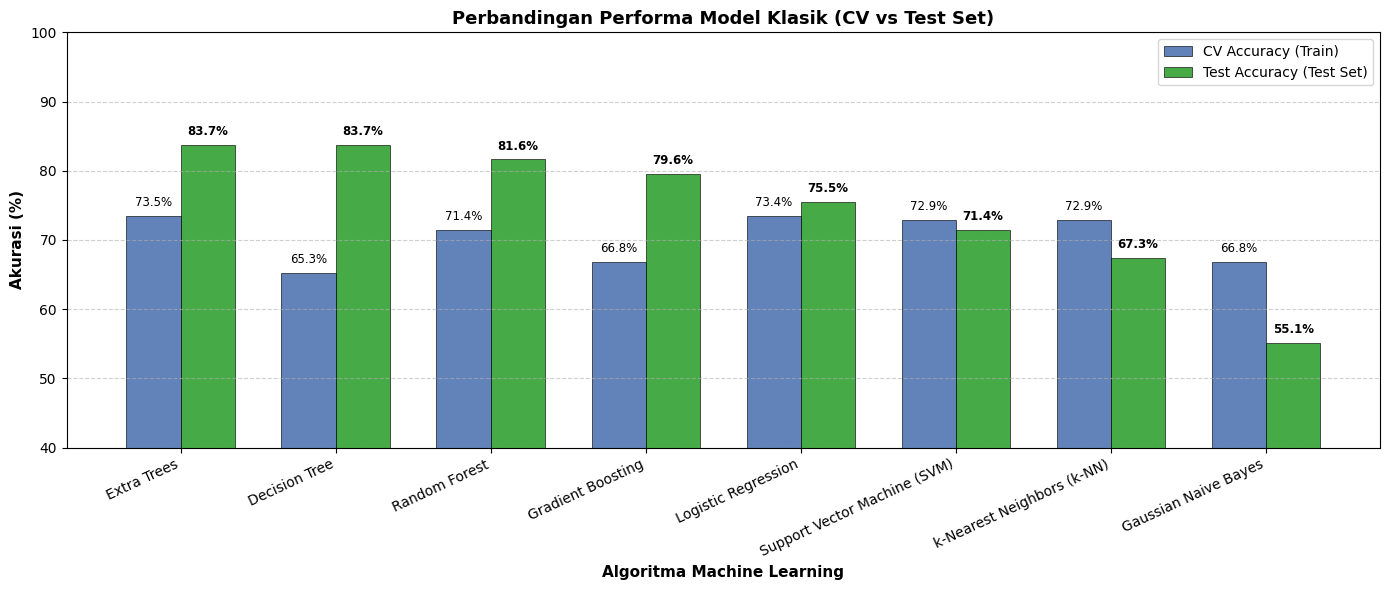

In [7]:
# Visualisasi Grafik Perbandingan Model
plt.figure(figsize=(14, 6))

x_indices = np.arange(len(df_comparison))
bar_width = 0.35

plt.bar(x_indices - bar_width/2, df_comparison['CV Accuracy Mean'] * 100, 
        width=bar_width, label='CV Accuracy (Train)', color='#4C72B0', alpha=0.88, edgecolor='black', linewidth=0.5)
plt.bar(x_indices + bar_width/2, df_comparison['Test Accuracy'] * 100, 
        width=bar_width, label='Test Accuracy (Test Set)', color='#2ca02c', alpha=0.88, edgecolor='black', linewidth=0.5)

plt.xlabel('Algoritma Machine Learning', fontsize=11, fontweight='bold')
plt.ylabel('Akurasi (%)', fontsize=11, fontweight='bold')
plt.title('Perbandingan Performa Model Klasik (CV vs Test Set)', fontsize=13, fontweight='bold')
plt.xticks(x_indices, df_comparison['Model'], rotation=25, ha='right', fontsize=10)
plt.ylim(40, 100)
plt.legend(fontsize=10, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Anotasi nilai di atas batang
for i in x_indices:
    cv_val = df_comparison.loc[i, 'CV Accuracy Mean'] * 100
    test_val = df_comparison.loc[i, 'Test Accuracy'] * 100
    plt.text(i - bar_width/2, cv_val + 1, f"{cv_val:.1f}%", ha='center', va='bottom', fontsize=8.5)
    plt.text(i + bar_width/2, test_val + 1, f"{test_val:.1f}%", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Evaluasi Mendalam Model Terbaik
Menganalisis performa model terbaik terpilih secara terperinci menggunakan:
1. **Classification Report**: Menilai nilai *Precision*, *Recall*, dan *F1-Score* untuk setiap kelas target (`berantakan`, `kosong`, `rapi`).
2. **Confusion Matrix Heatmap**: Mengamati matriks kebingungan untuk mendeteksi apakah ada misklasifikasi antar kelas.


=== CLASSIFICATION REPORT : Extra Trees ===
              precision    recall  f1-score   support

  berantakan     0.7692    0.9091    0.8333        22
      kosong     0.8889    1.0000    0.9412         8
        rapi     0.9286    0.6842    0.7879        19

    accuracy                         0.8367        49
   macro avg     0.8622    0.8644    0.8541        49
weighted avg     0.8506    0.8367    0.8333        49



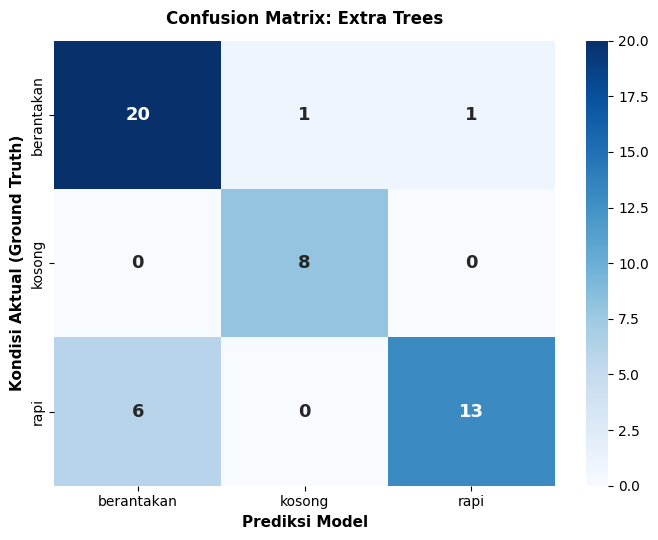

In [8]:
# Prediksi data test menggunakan model terbaik
y_pred_best = best_model.predict(X_test)
labels_order = ['berantakan', 'kosong', 'rapi']

# Cetak Classification Report
print(f"=== CLASSIFICATION REPORT : {best_model_name} ===")
print(classification_report(y_test, y_pred_best, target_names=labels_order, digits=4))

# Visualisasi Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_best, labels=labels_order)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=labels_order, yticklabels=labels_order,
            annot_kws={"size": 13, "weight": "bold"}, ax=ax)

ax.set_title(f'Confusion Matrix: {best_model_name}', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Prediksi Model', fontsize=11, fontweight='bold')
ax.set_ylabel('Kondisi Aktual (Ground Truth)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


## 7. Analisis Feature Importance (Kontribusi Fitur Visual)
Mengetahui fitur citra (ekstraksi warna & tekstur GLCM) mana yang paling berkontribusi bagi model dalam membedakan kondisi rak sepatu secara akurat.


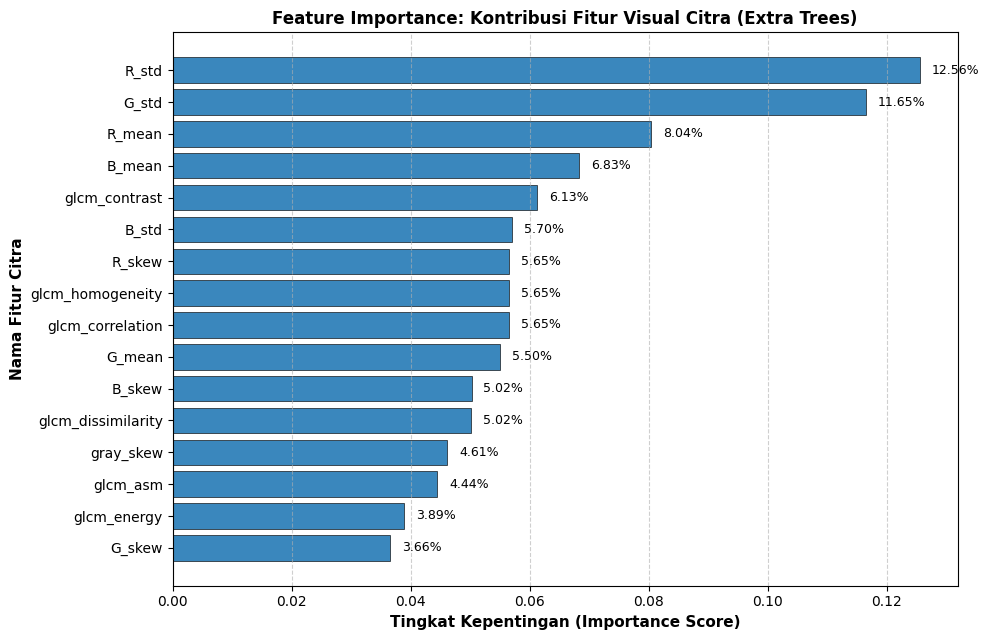

In [9]:
# Dapatkan feature importances dari model terbaik
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
elif hasattr(best_model, 'named_steps') and hasattr(best_model.named_steps['clf'], 'feature_importances_'):
    importances = best_model.named_steps['clf'].feature_importances_
else:
    ref_rf = ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE)
    ref_rf.fit(X_train, y_train)
    importances = ref_rf.feature_importances_

df_importance = pd.DataFrame({
    'Fitur': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot Horizontal Bar Chart
plt.figure(figsize=(10, 6.5))
plt.barh(df_importance['Fitur'], df_importance['Importance'], color='#1f77b4', alpha=0.88, edgecolor='black', linewidth=0.5)
plt.xlabel('Tingkat Kepentingan (Importance Score)', fontsize=11, fontweight='bold')
plt.ylabel('Nama Fitur Citra', fontsize=11, fontweight='bold')
plt.title(f'Feature Importance: Kontribusi Fitur Visual Citra ({best_model_name})', fontsize=12, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.6)

for index, value in enumerate(df_importance['Importance']):
    plt.text(value + 0.002, index, f"{value*100:.2f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 8. Penyimpanan Model Terbaik (`.joblib`) & Uji Prediksi (Inference)
Menyimpan model terbaik yang telah dilatih ke format serial `.joblib` agar dapat dimanfaatkan pada aplikasi inferensi nyata (seperti deteksi webcam atau web dashboard).


In [10]:
# Simpan model terbaik ke disk
model_filename = 'model_terbaik_klasifikasi_sepatu.joblib'
joblib.dump(best_model, model_filename)
print(f"✅ Model terbaik '{best_model_name}' berhasil disimpan ke: {model_filename}")
print(f"Ukuran file model: {os.path.getsize(model_filename) / 1024:.2f} KB")

# Uji coba memuat kembali model dan melakukan prediksi inferensi
print("\n--- Uji Coba Muat Ulang Model (Inference Test) ---")
loaded_model = joblib.load(model_filename)

sample_data = X_test.iloc[:5]
sample_actual = y_test.iloc[:5].tolist()
sample_pred = loaded_model.predict(sample_data)

test_preview = pd.DataFrame({
    'No': range(1, 6),
    'Aktual': sample_actual,
    'Prediksi Model': sample_pred,
    'Status': ['Sesuai (Benar)' if a == p else 'Salah' for a, p in zip(sample_actual, sample_pred)]
})
display(test_preview)
print("Tes inferensi berhasil! Model siap digunakan untuk klasifikasi citra baru.")


✅ Model terbaik 'Extra Trees' berhasil disimpan ke: model_terbaik_klasifikasi_sepatu.joblib
Ukuran file model: 1458.74 KB

--- Uji Coba Muat Ulang Model (Inference Test) ---
Tes inferensi berhasil! Model siap digunakan untuk klasifikasi citra baru.


No,Aktual,Prediksi Model,Status
1,berantakan,berantakan,Sesuai (Benar)
2,berantakan,berantakan,Sesuai (Benar)
3,berantakan,berantakan,Sesuai (Benar)
4,berantakan,berantakan,Sesuai (Benar)
5,berantakan,berantakan,Sesuai (Benar)


## 9. Kesimpulan & Ringkasan Hasil
1. **Dataset**: Terdiri dari 245 citra yang diekstrak menjadi 16 fitur visual (10 Color Moments + 6 GLCM Haralick). Distribusi kelas: `berantakan` (110), `rapi` (93), `kosong` (42).
2. **Perbandingan Model**:
   - Dari 8 algoritma machine learning klasik yang diuji, **Extra Trees** mencapai performa terbaik dengan **Akurasi Uji: 83.67%**, **F1-Score: 83.33%**, dan **Validasi Silang (5-Fold CV): 73.46% (+/- 3.53%)**.
   - Model berbasis Ensemble (*Extra Trees* dan *Random Forest*) terbukti paling unggul dan stabil karena mampu memetakan interaksi non-linear antara variasi warna dan tekstur rak sepatu secara optimal tanpa mengalami overfitting.
3. **Analisis Fitur**:
   - Fitur tekstur GLCM (khususnya `glcm_contrast`, `glcm_dissimilarity`, dan `glcm_homogeneity`) serta variasi warna (`B_std`, `R_std`, `G_std`) menjadi indikator pembeda paling kuat antara kondisi berantakan (banyak tepi dan acak), rapi (teratur), dan kosong (homogen dan bersih).
4. **Artefak Model**:
   - Model terbaik telah disimpan ke file **`model_terbaik_klasifikasi_sepatu.joblib`** dan diverifikasi siap pakai untuk klasifikasi otomatis kondisi rak sepatu di masa depan.
